# v2.06 — v2.04 without a price head (trend only; validation only)

**One change on top of v2.04**, the adopted baseline (Siwat, 2026-11-02, `configs/v2_06.json`):
- **What changes:** the price head and the price loss are removed. The model learns the trend task only.
- **What stays:** everything else is exactly v2.04, including news-robust training (p 0.2, whole window).

**Why:** v2.05 (price weight 0.25) was not adopted. E11b (2026-10-16, older model) gained +0.017 at 5 days without the price loss. v2.06 tests that on the current model.

**Ablation:** the signed proposal requires a trained price head (L5 / L6). If v2.06 is adopted, v3 still needs a price head brought back, for example a stop-gradient head trained on the frozen shared layers, which would not change the trend model.

**Runtime:** A100 or L4, Colab only (Linux). Runtime → Run all. About 1 h of training, then about 10 min for the post-hoc step and the comparison.

**Adopt rule** (pre-registered, `claude/log-entry-2026-11-02-v2-06-design.md`), raw models vs v2.04:
- **(a)** news-on: the paired 95% interval of v2.06 − v2.04 (3-horizon mean) is entirely above 0;
- **(b)** news-blanked: that interval is not entirely below 0.

Outputs: `Senior/results/v2xx/<GPU>/v2_06*`, `Senior/results/v2_06_posthoc/`, `Senior/results/v2_06_vs_v2_04.json`. Test block sealed.

In [1]:
!nvidia-smi -L
import torch
name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'none'
mem = torch.cuda.get_device_properties(0).total_memory / 2**30 if torch.cuda.is_available() else 0
print(f'GPU: {name}, {mem:.0f} GB')
GPU_TAG = 'A100' if 'A100' in name else 'L4' if 'L4' in name else None
assert GPU_TAG, 'stop: switch the runtime to an A100 or L4 GPU (Runtime -> Change runtime type)'

GPU 0: NVIDIA A100-SXM4-40GB (UUID: GPU-39bad4d4-0690-6fb0-212c-3246b26ea3c1)
GPU: NVIDIA A100-SXM4-40GB, 39 GB


In [2]:
from google.colab import drive
drive.mount('/content/drive')
import hashlib, json, os, subprocess, sys
from pathlib import Path
SENIOR = '/content/drive/MyDrive/Senior'
PRICE_DIR, RES = f'{SENIOR}/prices', f'{SENIOR}/results'
OUT = f'{RES}/v2xx/{GPU_TAG}'
V206 = f'{OUT}/v2_06.json'
POST = f'{RES}/v2_06_posthoc'                      # v2.06's post-hoc step
BASE = f'{RES}/v2_04_posthoc'                      # v2.04's post-hoc step, the comparison
BASE_RUN = f'{RES}/v2xx/A100/v2_04.json'           # v2.04's run (A100, 2026-10-27)
FWD_INPUTS = f'{RES}/forward_2026/inputs'
for f in [f'{BASE}/step0.json', f'{BASE}/trees.csv.gz', f'{BASE}/parts/val_blank.csv.gz', BASE_RUN, f'{FWD_INPUTS}/forward_prices.csv',
          f'{PRICE_DIR}/set50_union_2019_2025.csv', f'{PRICE_DIR}/yahoo_events_2019_2025.csv']:
    assert os.path.exists(f), f'stop: missing {f}'
os.makedirs(OUT, exist_ok=True)

def stream(args):
    # stream a script's output into the notebook and stop on failure
    p = subprocess.Popen(args, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    for line in p.stdout:
        if 'defined on' not in line and 'not writable' not in line and 'from_numpy' not in line:
            print(line, end='', flush=True)
    if p.wait() != 0:
        raise SystemExit(f'stop: {" ".join(args[1:3])} failed (exit {p.returncode}); see the lines above')

Mounted at /content/drive


In [3]:
!rm -rf /content/Senior-Project && git clone -q https://github.com/Smith8bit/Senior-Project.git /content/Senior-Project
%cd /content/Senior-Project
!git log --oneline -1
for f in ['configs/v2_06.json', 'scripts/train_v2xx.py', 'src/train_utils.py', 'src/run_config.py', 'tests/test_no_price_head.py', 'src/proposal_model.py',
          'scripts/step0_v2_03beta.py', 'scripts/compare_v2xx_posthoc.py', 'scripts/plot_v2xx_training.py']:
    assert os.path.exists(f), f'stop: push the v2.06 code first ({f} missing)'
    print(f, hashlib.sha256(open(f, 'rb').read()).hexdigest()[:12])
!mkdir -p data/raw/prices/siamchart data/raw/prices/yahoo
!cp "$PRICE_DIR/set50_union_2019_2025.csv" data/raw/prices/siamchart/
!cp "$PRICE_DIR/yahoo_events_2019_2025.csv" data/raw/prices/yahoo/
expected = {'data/raw/prices/siamchart/set50_union_2019_2025.csv': '9d7ce4c3e72a974979566dc089d5b8819af54dc24f62b71240f5b4716b556e6f',
            'data/raw/prices/yahoo/yahoo_events_2019_2025.csv': 'd021a58df95fa487f1e49eb50617f6b3187b025b6377235c6180166b1ec84d53',
            'data/derived/sentiment_scores.csv': '7369fd981c4ccffc017d6d5de50ed95c6a4ac4d843bbc6053366029ce614bb1b'}
for path, h in expected.items():
    got = hashlib.sha256(open(path, 'rb').read()).hexdigest()
    print('OK ' if got == h else 'MISMATCH ', path)
    assert got == h, 'stop: a file differs from the frozen copy'
sys.path.insert(0, 'src'); sys.path.insert(0, 'scripts')
import run_config as RC
cfg = RC.load('configs/v2_06.json')
print('v2.06 price head:', cfg['model']['price_head'], '| loss:', json.dumps(cfg['loss']), '| training:', json.dumps(cfg['training']))

/content/Senior-Project
c1945f3 (HEAD -> main, origin/main, origin/HEAD) Add v2.06 trend-only price-head ablation
configs/v2_06.json 7d558fdae26d
scripts/train_v2xx.py ad4fd58ae725
src/train_utils.py a1679e2d17f8
src/run_config.py a62511ee3eb2
tests/test_no_price_head.py ee2a4d4cfef5
src/proposal_model.py a1335af76a33
scripts/step0_v2_03beta.py 7e123773e93e
scripts/compare_v2xx_posthoc.py b6a4f3e0fdea
scripts/plot_v2xx_training.py 40f9f80b2d99
OK  data/raw/prices/siamchart/set50_union_2019_2025.csv
OK  data/raw/prices/yahoo/yahoo_events_2019_2025.csv
OK  data/derived/sentiment_scores.csv
v2.06 price head: False | loss: {"price_target": "log_return", "weighting": "fixed", "w_trend": 1.0, "w_price": 0, "price_loss": "mse", "huber_delta": null} | training: {"lr": 0.0001, "lr_schedule": "constant", "weight_decay": 0.01, "batch_size": 256, "max_epochs": 30, "early_stopping": true, "stop_rule": "mean", "patience": 5, "grad_clip": 0, "checkpoint": "shared", "selection": "f1_mean", "weight_ave

In [4]:
# Tests (about 7 minutes); the notebook stops if any fails
for t in ['tests/test_v2xx.py', 'tests/test_v2xx_training.py', 'tests/test_news_blank.py', 'tests/test_grad_diag.py', 'tests/test_no_price_head.py',
          'tests/test_step0_v2_03beta.py']:
    r = subprocess.run(['python', t], capture_output=True, text=True)
    print(f'--- {t}'); print('\n'.join(l for l in r.stdout.splitlines() if 'defined on' not in l and '    seed' not in l)[-2500:])
    assert r.returncode == 0 and 'FAIL' not in r.stdout, f'stop: {t} failed\n' + r.stderr[-2000:]

--- tests/test_v2xx.py
 91,841 equals the hand formula
PASS batchnorm/independent: both heads receive gradient
PASS batchnorm/mixed: output shapes
PASS batchnorm/mixed: scale weights are a softmax
PASS batchnorm/mixed: heads 128->128->64->3 / ->9 and Linear layer 128 (slides 12-13)
PASS batchnorm/mixed: weight count 67,841 equals the hand formula
PASS batchnorm/mixed: both heads receive gradient
PASS independent: day t always reaches the output; the leftover oldest day is the one dropped
PASS mixed: day t always reaches the output; the leftover oldest day is the one dropped
PASS v2.01 numbers: tokens 126 / 25 / 6; the week scale skips the oldest day
PASS v2.01 numbers: weight count 1,587,175 equals the hand formula
PASS v2.02 numbers: tokens 63 / 25 / 6, weight count 1,579,239 = hand formula = 1,579,239
PASS PatchTST layer: BatchNorm1d over d_model, GELU feed-forward, attention dropout 0 (official defaults)
PASS post-norm order: normalise after each residual add
PASS eval mode: a row's

In [5]:
# 1. Train v2.06 (no price head): 3 seeds one after another
def done(path, n=3):
    try:
        r = json.load(open(path)); return len(r['runs']) == n and 'summary' in r
    except Exception:
        return False
if done(V206):
    print('v2.06: already trained')
else:
    stream(['python', '-u', 'scripts/train_v2xx.py', '--config', 'configs/v2_06.json', '--out', V206])

config v2.06: {"inputs": {"price_channels": ["open", "high", "low", "close", "volume"], "ohlc_return_base": "previous_close", "indicators": ["sma", "ema", "rsi", "macd", "bb_pctb", "adx"], "sma_periods": [9, 21, 60], "ema_periods": [9, 21, 60], "rsi_period": 14, "macd_fast": 12, "macd_slow": 26, "bb_period": 20, "bb_width_k": 2.0, "adx_period": 14, "sentiment": ["p_pos", "p_neg", "p_neu"], "sentiment_no_news": "uniform", "stock_identity": ["stock_id", "sector_id"]}, "model": {"family": "proposal_msp", "lookback": 126, "patch_lengths": [2, 5, 21], "patch_strides": [2, 5, 21], "channel_mode": "independent", "revin": true, "encoder_norm": "batchnorm", "d_model": 128, "n_heads": 16, "n_layers": 3, "d_ff": 256, "dropout": 0.2, "pooling": "mean", "scale_fusion": "attention", "fusion_hidden": 128, "d_stock": 32, "d_sector": 18, "stock_id_dropout": 0.1, "trunk_width": 128, "head_hidden": [128, 64], "head_dropout": 0.2, "price_head": false}, "loss": {"price_target": "log_return", "weighting": "

                v2.06 F1   v2.04    bar  continues  reverses
h1         0.3550 ± 0.0080  0.3391  0.393      0.352     0.373
h5         0.3639 ± 0.0095  0.3692  0.400      0.344     0.364
h10        0.3728 ± 0.0066  0.3721  0.407      0.387     0.333
seed 4539913 epochs 16 kept 11 hold-out F1 0.3794 weights 1554276 minutes 17.3
seed 9574315 epochs 20 kept 15 hold-out F1 0.3846 weights 1554276 minutes 21.6
seed 2253758 epochs 16 kept 11 hold-out F1 0.3793 weights 1554276 minutes 17.3
saved /content/drive/MyDrive/Senior/results/v2xx/A100/v2_06_training.png


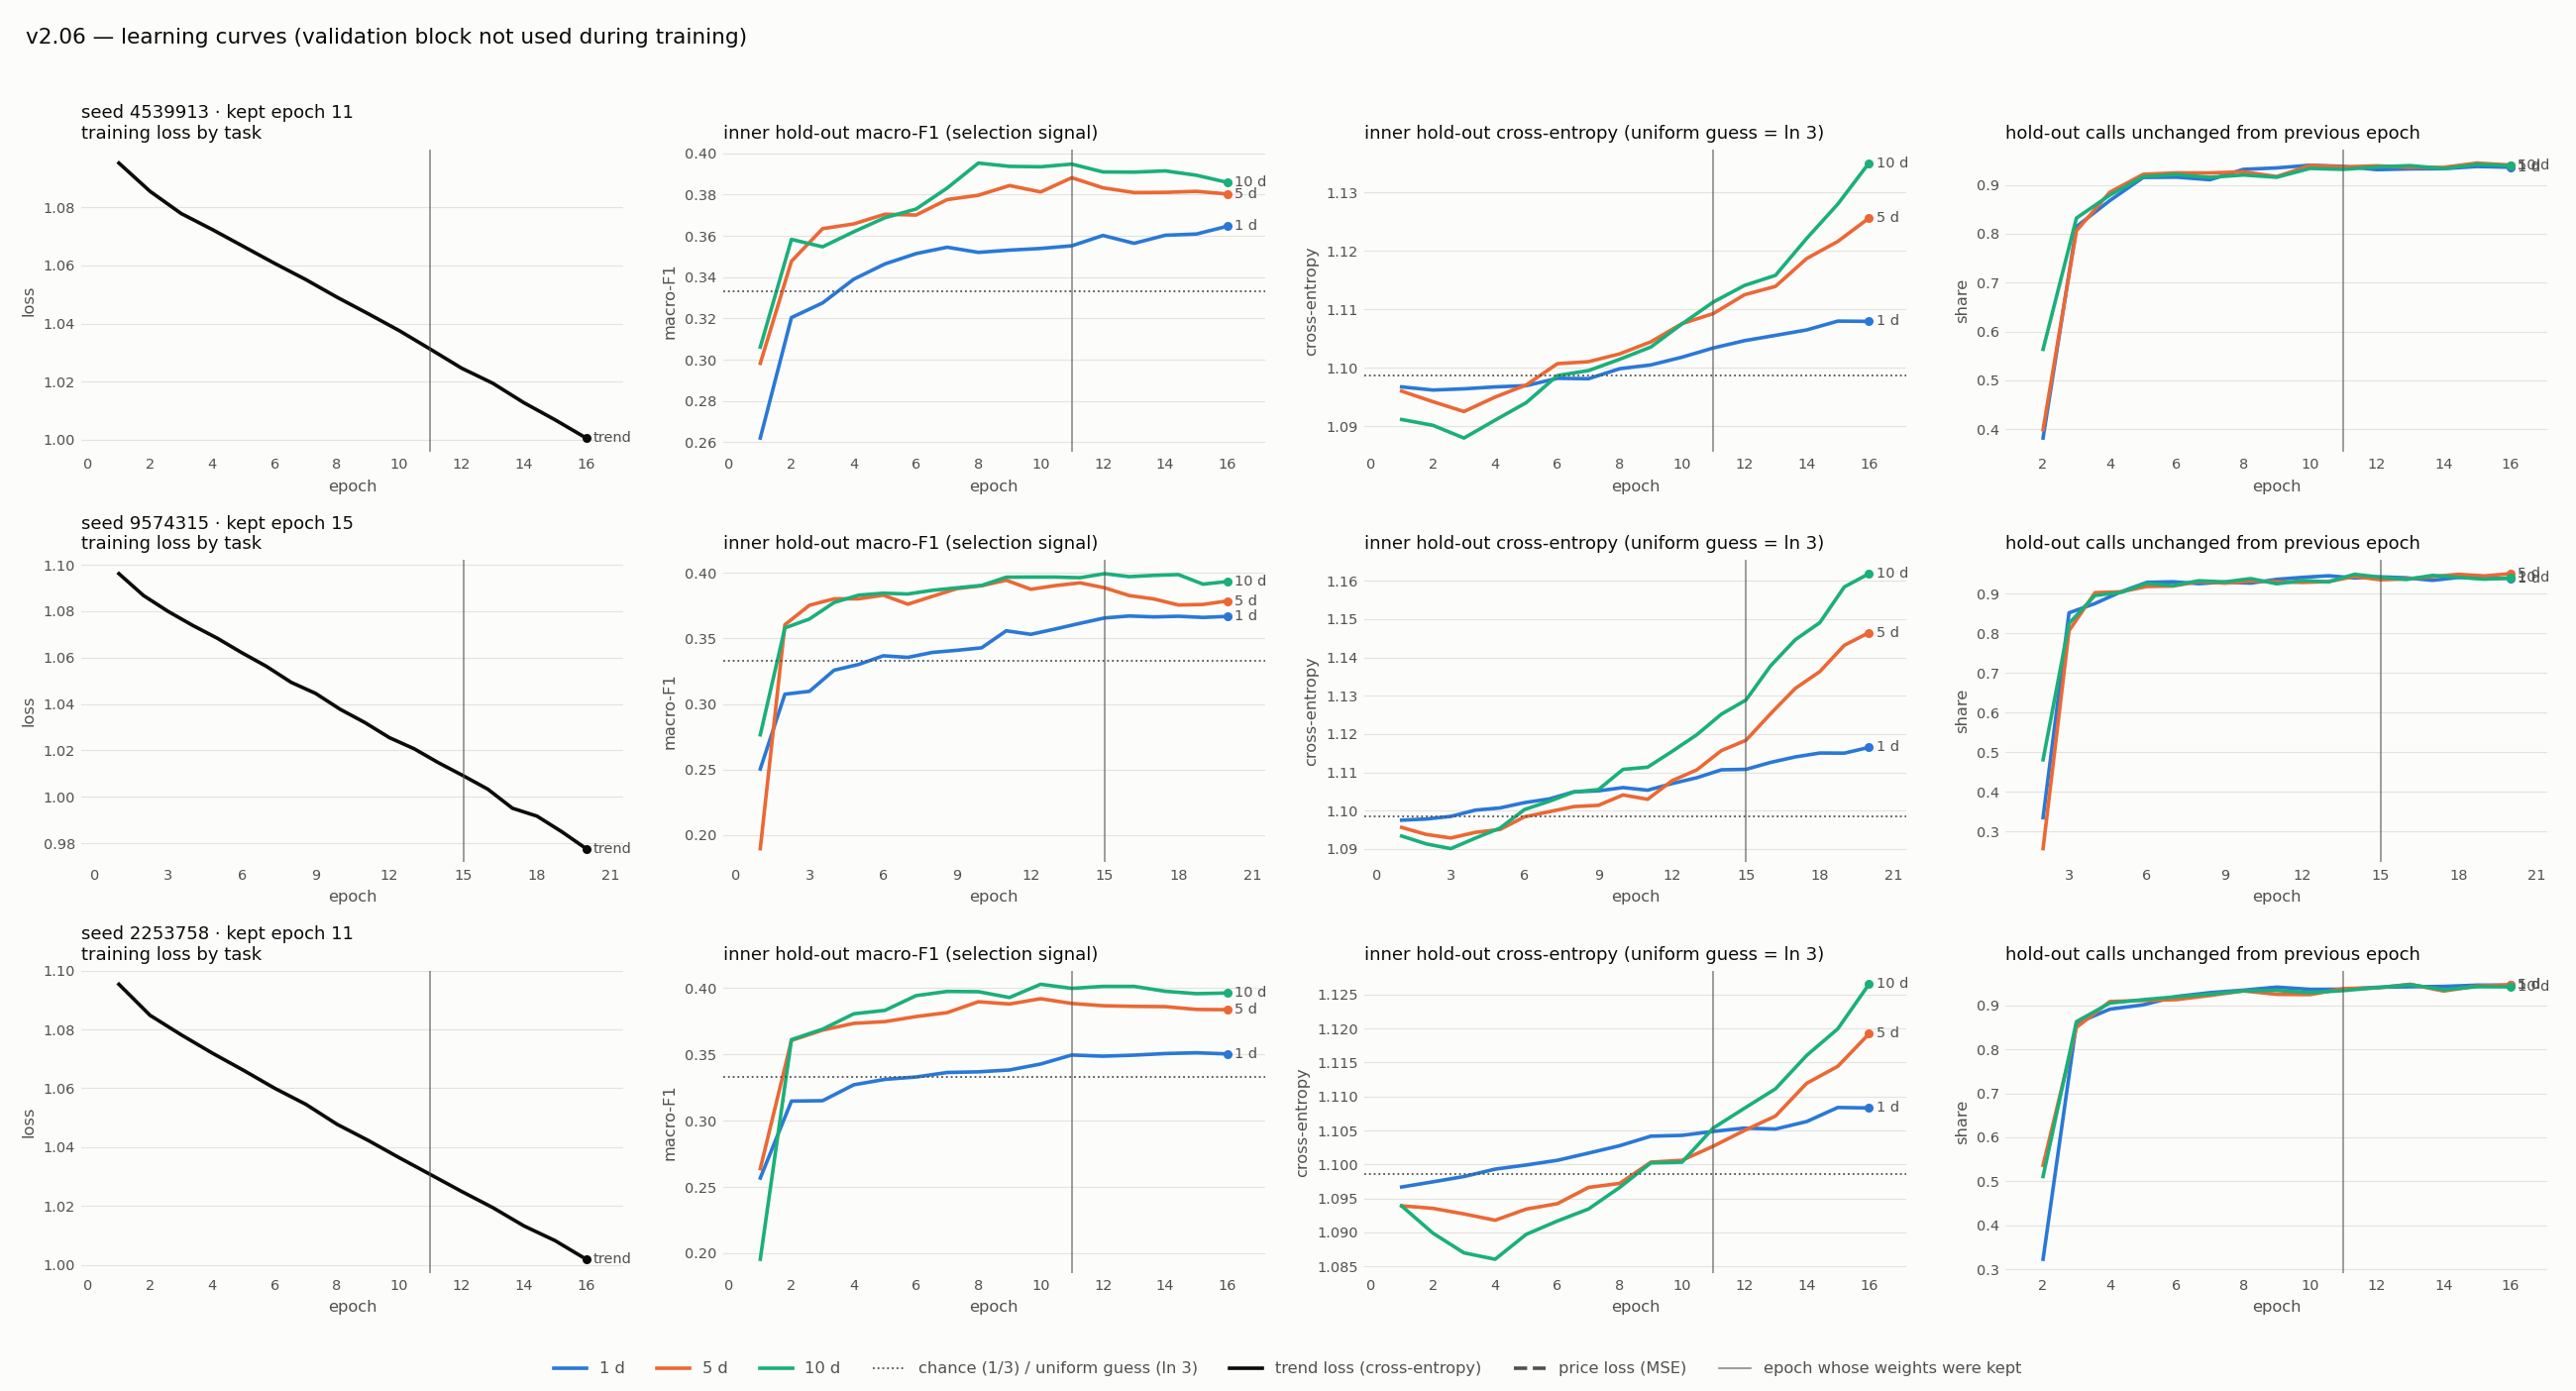

saved /content/drive/MyDrive/Senior/results/v2xx/A100/v2_06_calls.png


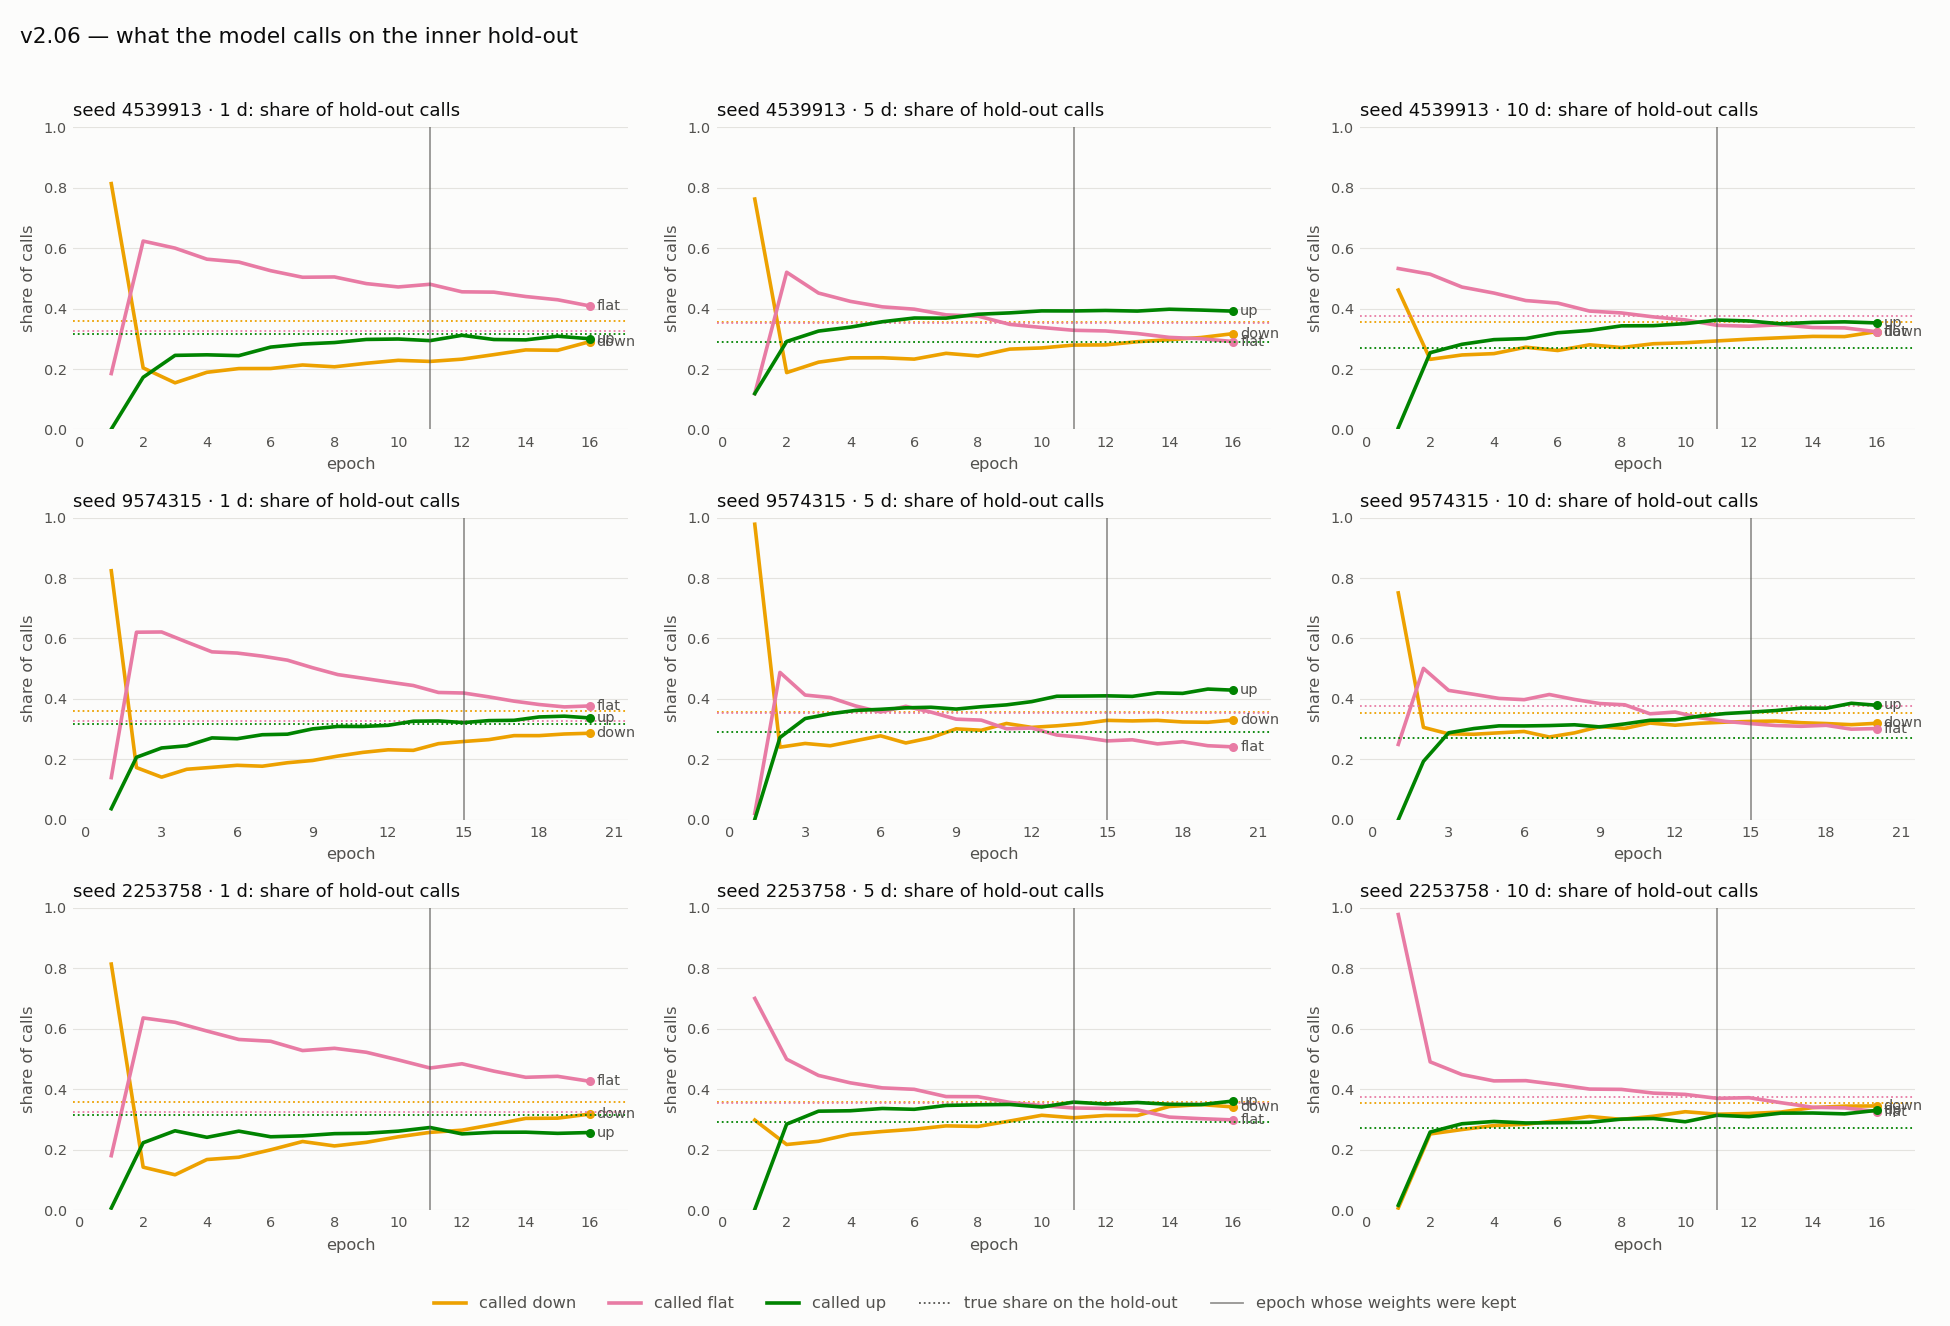

In [6]:
# 2. Summary beside v2.04 and the floors (no price metrics: v2.06 has no price head), and the learning curves
r = json.load(open(V206)); s, fl = r['summary']['model'], r['floors']
b = json.load(open(BASE_RUN))['summary']['model']
BAR = {'h1': 0.393, 'h5': 0.400, 'h10': 0.407}
print(f"{'':6}{'v2.06 F1':>18}{'v2.04':>8}{'bar':>7}{'continues':>11}{'reverses':>10}")
for h in ('h1', 'h5', 'h10'):
    m = s[h]
    print(f"{h:6}{m['macro_f1']['mean']:>11.4f} ± {m['macro_f1']['std']:.4f}{b[h]['macro_f1']['mean']:>8.4f}{BAR[h]:>7.3f}"
          f"{fl[h]['trend_continues']['macro_f1']:>11.3f}{fl[h]['trend_reverses']['macro_f1']:>10.3f}")
for x in r['runs']:
    print('seed', x['seed'], 'epochs', x['epochs_run'], 'kept', x['best_epoch'], 'hold-out F1', x['best_inner_es_macro_f1'],
          'weights', x['params']['total'], 'minutes', round(x['seconds'] / 60, 1))
from IPython.display import Image, display
import importlib, plot_v2xx_training as PT
for png in (PT.plot(Path(V206)), PT.plot_calls(Path(V206))):
    if png:
        print('saved', png); display(Image(filename=str(png)))

In [ ]:
# 3. Post-hoc step for v2.06 (same script and settings as v2.03beta-v2.05): reproduction check, ts, blend (w on v2.06's
#    own inner hold-out), news blanked and placebo, on validation and 2026
common = ['--run-json', V206, '--fwd-inputs', FWD_INPUTS, '--out-dir', POST, '--label', 'v2.06 post-hoc']
for stage in ('prepare', 'predict', 'trees', 'analyze'):
    stream(['python', 'scripts/step0_v2_03beta.py', stage, *common])

2026 members: 54 symbols; with no frozen price history: ['MRDIYT', 'TFG', 'THAI']
reusing saved forward inputs in /content/drive/MyDrive/Senior/results/v2_06_posthoc/inputs (pass --refresh to fetch again)
forward price rows: 13107 after 2025-12-30, last day 2026-10-15, 191 trading days
breaks added (new tickers, or 2026 rows): {'BANPU': ['2026-01-05'], 'THAI': ['2021-04-16', '2025-08-04']}
large moves kept (|log r| 0.18-0.300), check against SET corporate actions: [{'symbol': 'BANPU', 'date': '2026-08-05', 'log_return': 0.2298}, {'symbol': 'JMART', 'date': '2026-05-15', 'log_return': 0.1982}, {'symbol': 'MRDIYT', 'date': '2026-06-30', 'log_return': 0.2661}, {'symbol': 'MRDIYT', 'date': '2026-07-01', 'log_return': -0.1989}, {'symbol': 'THAI', 'date': '2021-05-17', 'log_return': 0.26}, {'symbol': 'VGI', 'date': '2026-02-13', 'log_return': 0.2031}]
  note: 2026 splits fetched before the frozen events file was made (2026-09-25): [{'symbol': 'GLOBAL', 'date': 20260224, 'event': 'split', 'va

In [ ]:
# 4. v2.06 vs v2.04 on the same rows, and the pre-registered adopt rule (news-on gain significant; blanked held)
stream(['python', 'scripts/compare_v2xx_posthoc.py', '--base', BASE, '--new', POST, '--rule', 'trend_up_significant',
        '--out', f'{RES}/v2_06_vs_v2_04.json'])

**Reading the result**
- **ADOPT RULE** (last block): (a) the news-on gain over v2.04 is significant (interval entirely above 0), and (b) news-blanked doesn't fall significantly. Raw models.
- No price metrics: v2.06 has no price head. v2.04's price R² is −0.034 for reference.
- **ts + blend** and **2026** are reported beside it, as before.
- Send the printout to Claude.